# US Accidents Exploratory Data Analysis

### Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Load Dataset

In [2]:
data = pd.read_csv('/kaggle/input/datasets/sobhanmoosavi/us-accidents/US_Accidents_March23.csv')
df = data.copy()

### Display First 5 Rows

In [3]:
df.head()

,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),...,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
0,A-1,Source2,3,2016-02-08 05:46:00,2016-02-08 11:00:00,39.865147,-84.058723,NaN,NaN,0.01,...,False,False,False,False,False,False,Night,Night,Night,Night
1,A-2,Source2,2,2016-02-08 06:07:59,2016-02-08 06:37:59,39.928059,-82.831184,NaN,NaN,0.01,...,False,False,False,False,False,False,Night,Night,Night,Day
2,A-3,Source2,2,2016-02-08 06:49:27,2016-02-08 07:19:27,39.063148,-84.032608,NaN,NaN,0.01,...,False,False,False,False,True,False,Night,Night,Day,Day
3,A-4,Source2,3,2016-02-08 07:23:34,2016-02-08 07:53:34,39.747753,-84.205582,NaN,NaN,0.01,...,False,False,False,False,False,False,Night,Day,Day,Day
4,A-5,Source2,2,2016-02-08 07:39:07,2016-02-08 08:09:07,39.627781,-84.188354,NaN,NaN,0.01,...,False,False,False,False,True,False,Day,Day,Day,Day


### Dataset Dimensions

In [4]:
df.shape

(7728394, 46)

### Dataset Information

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7728394 entries, 0 to 7728393
Data columns (total 46 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   ID                     object 
 1   Source                 object 
 2   Severity               int64  
 3   Start_Time             object 
 4   End_Time               object 
 5   Start_Lat              float64
 6   Start_Lng              float64
 7   End_Lat                float64
 8   End_Lng                float64
 9   Distance(mi)           float64
 10  Description            object 
 11  Street                 object 
 12  City                   object 
 13  County                 object 
 14  State                  object 
 15  Zipcode                object 
 16  Country                object 
 17  Timezone               object 
 18  Airport_Code           object 
 19  Weather_Timestamp      object 
 20  Temperature(F)         float64
 21  Wind_Chill(F)          float64
 22  Humidity(%)       

### Statistical Summary

In [6]:
df.describe()

,Severity,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in)
count,7.728394e+06,7.728394e+06,7.728394e+06,4.325632e+06,4.325632e+06,7.728394e+06,7.564541e+06,5.729375e+06,7.554250e+06,7.587715e+06,7.551296e+06,7.157161e+06,5.524808e+06
mean,2.212384e+00,3.620119e+01,-9.470255e+01,3.626183e+01,-9.572557e+01,5.618423e-01,6.166329e+01,5.825105e+01,6.483104e+01,2.953899e+01,9.090376e+00,7.685490e+00,8.407210e-03
std,4.875313e-01,5.076079e+00,1.739176e+01,5.272905e+00,1.810793e+01,1.776811e+00,1.901365e+01,2.238983e+01,2.282097e+01,1.006190e+00,2.688316e+00,5.424983e+00,1.102246e-01
min,1.000000e+00,2.455480e+01,-1.246238e+02,2.456601e+01,-1.245457e+02,0.000000e+00,-8.900000e+01,-8.900000e+01,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2.000000e+00,3.339963e+01,-1.172194e+02,3.346207e+01,-1.177543e+02,0.000000e+00,4.900000e+01,4.300000e+01,4.800000e+01,2.937000e+01,1.000000e+01,4.600000e+00,0.000000e+00
50%,2.000000e+00,3.582397e+01,-8.776662e+01,3.618349e+01,-8.802789e+01,3.000000e-02,6.400000e+01,6.200000e+01,6.700000e+01,2.986000e+01,1.000000e+01,7.000000e+00,0.000000e+00
75%,2.000000e+00,4.008496e+01,-8.035368e+01,4.017892e+01,-8.024709e+01,4.640000e-01,7.600000e+01,7.500000e+01,8.400000e+01,3.003000e+01,1.000000e+01,1.040000e+01,0.000000e+00
max,4.000000e+00,4.900220e+01,-6.711317e+01,4.907500e+01,-6.710924e+01,4.417500e+02,2.070000e+02,2.070000e+02,1.000000e+02,5.863000e+01,1.400000e+02,1.087000e+03,3.647000e+01


### Missing Values Count

In [7]:
df.isnull().sum()

ID                             0
Source                         0
Severity                       0
Start_Time                     0
End_Time                       0
Start_Lat                      0
Start_Lng                      0
End_Lat                  3402762
End_Lng                  3402762
Distance(mi)                   0
Description                    5
Street                     10869
City                         253
County                         0
State                          0
Zipcode                     1915
Country                        0
Timezone                    7808
Airport_Code               22635
Weather_Timestamp         120228
Temperature(F)            163853
Wind_Chill(F)            1999019
Humidity(%)               174144
Pressure(in)              140679
Visibility(mi)            177098
Wind_Direction            175206
Wind_Speed(mph)           571233
Precipitation(in)        2203586
Weather_Condition         173459
Amenity                        0
Bump      

### Missing Values Percentage

In [8]:
(df.isnull().sum() / len(df)) * 100

ID                        0.000000
Source                    0.000000
Severity                  0.000000
Start_Time                0.000000
End_Time                  0.000000
Start_Lat                 0.000000
Start_Lng                 0.000000
End_Lat                  44.029355
End_Lng                  44.029355
Distance(mi)              0.000000
Description               0.000065
Street                    0.140637
City                      0.003274
County                    0.000000
State                     0.000000
Zipcode                   0.024779
Country                   0.000000
Timezone                  0.101030
Airport_Code              0.292881
Weather_Timestamp         1.555666
Temperature(F)            2.120143
Wind_Chill(F)            25.865904
Humidity(%)               2.253301
Pressure(in)              1.820288
Visibility(mi)            2.291524
Wind_Direction            2.267043
Wind_Speed(mph)           7.391355
Precipitation(in)        28.512858
Weather_Condition   

### Check Duplicate Rows

In [9]:
df.duplicated().sum()

np.int64(0)

### Check Duplicate IDs

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df['ID'].duplicated().sum()

np.int64(0)

### Check Unique Values

In [12]:
df['Severity'].value_counts()

Severity
2    6156981
3    1299337
4     204710
1      67366
Name: count, dtype: int64

### Severity Percentage

In [13]:
df['Severity'].value_counts(normalize=True) * 100

Severity
2    79.667017
3    16.812510
4     2.648804
1     0.871669
Name: proportion, dtype: float64

### Explore Accident Sources

In [14]:
df['Source'].value_counts()

Source
Source1    4325632
Source2    3305373
Source3      97389
Name: count, dtype: int64

### Explore Weather Conditions

In [15]:
df['Weather_Condition'].value_counts()

Weather_Condition
Fair                         2560802
Mostly Cloudy                1016195
Cloudy                        817082
Clear                         808743
Partly Cloudy                 698972
                              ...   
Heavy Sleet / Windy                1
Sand / Windy                       1
Heavy Rain Shower / Windy          1
Blowing Snow Nearby                1
Drifting Snow                      1
Name: count, Length: 144, dtype: int64

### Explore States

In [16]:
df['State'].value_counts()

State
CA    1741433
FL     880192
TX     582837
SC     382557
NY     347960
NC     338199
VA     303301
PA     296620
MN     192084
OR     179660
AZ     170609
GA     169234
IL     168958
TN     167388
MI     162191
LA     149701
NJ     140719
MD     140417
OH     118115
WA     108221
AL     101044
UT      97079
CO      90885
OK      83647
MO      77323
CT      71005
IN      67224
MA      61996
WI      34688
KY      32254
NE      28870
MT      28496
IA      26307
AR      22780
NV      21665
KS      20992
DC      18630
RI      16971
MS      15181
DE      14097
WV      13793
ID      11376
NM      10325
NH      10213
WY       3757
ND       3487
ME       2698
VT        926
SD        289
Name: count, dtype: int64

In [19]:
df['Start_Time'] = pd.to_datetime(df['Start_Time'], format='mixed')
df['Start_Time'].dtype

dtype('<M8[ns]')

In [20]:
df['Year'] = df['Start_Time'].dt.year
df['Year'].value_counts().sort_index()

Year
2016     410821
2017     718093
2018     893426
2019     954303
2020    1178913
2021    1563753
2022    1762452
2023     246633
Name: count, dtype: int64

In [21]:
df['Month'] = df['Start_Time'].dt.month
df['Month'].value_counts().sort_index()

Month
1     751946
2     658984
3     554595
4     587300
5     558176
6     571373
7     512335
8     599666
9     651381
10    675130
11    760165
12    847343
Name: count, dtype: int64

In [22]:
df['Hour'] = df['Start_Time'].dt.hour
df['Hour'].value_counts().sort_index()

Hour
0     112378
1      97071
2      93227
3      83863
4     159852
5     228182
6     405837
7     587472
8     577576
9     363034
10    342706
11    355040
12    355001
13    396445
14    448846
15    525855
16    581969
17    576015
18    432042
19    295121
20    225226
21    191452
22    167645
23    126539
Name: count, dtype: int64

In [23]:
df.groupby(['Year', 'Severity']).size().unstack(fill_value=0)

Severity,1,2,3,4
Year,,,,
2016,225,270026,126215,14355
2017,282,462474,231169,24168
2018,259,574668,292706,25793
2019,203,688144,237853,28103
2020,28371,934123,185352,31067
2021,151,1384628,148085,30889
2022,37875,1603346,77957,43274
2023,0,239572,0,7061


### Accidents per Year

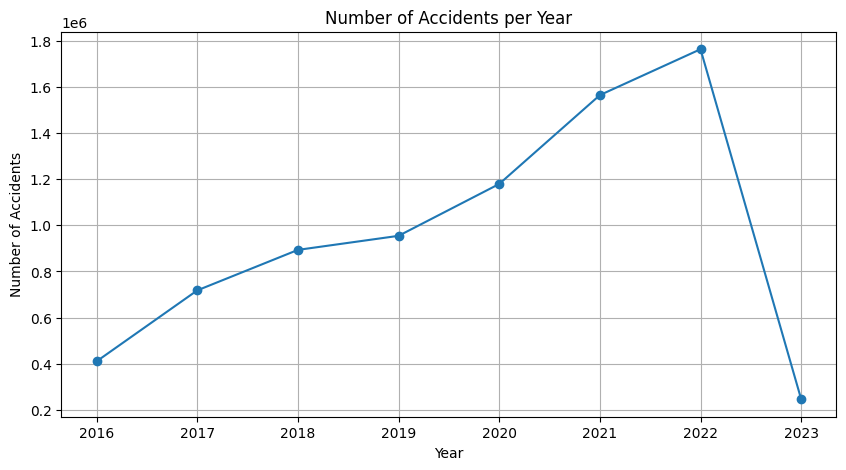

In [24]:
yearly_accidents = df['Year'].value_counts().sort_index()

plt.figure(figsize=(10, 5))
plt.plot(yearly_accidents.index, yearly_accidents.values, marker='o')

plt.title('Number of Accidents per Year')
plt.xlabel('Year')
plt.ylabel('Number of Accidents')
plt.xticks(yearly_accidents.index)
plt.grid(True)

plt.show()

### Accidents per Month

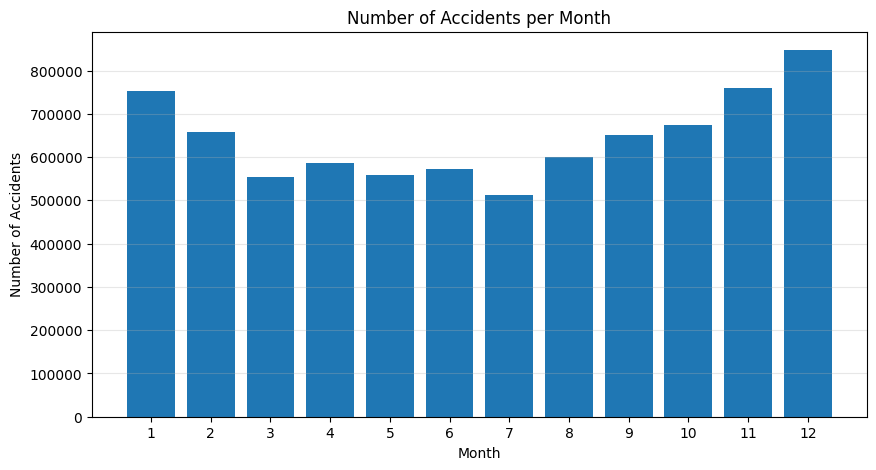

In [25]:
monthly_accidents = df['Month'].value_counts().sort_index()

plt.figure(figsize=(10, 5))
plt.bar(monthly_accidents.index, monthly_accidents.values)

plt.title('Number of Accidents per Month')
plt.xlabel('Month')
plt.ylabel('Number of Accidents')
plt.xticks(range(1, 13))
plt.grid(axis='y', alpha=0.3)

plt.show()

### Accidents by Hour (Seaborn)

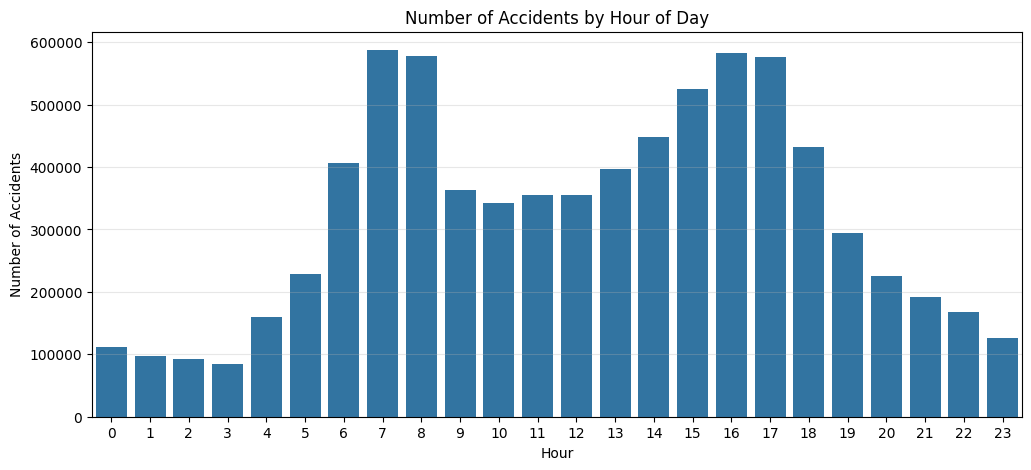

In [27]:
hourly_accidents = df['Hour'].value_counts().sort_index()

plt.figure(figsize=(12, 5))

sns.barplot(
    x=hourly_accidents.index,
    y=hourly_accidents.values
)

plt.title('Number of Accidents by Hour of Day')
plt.xlabel('Hour')
plt.ylabel('Number of Accidents')
plt.xticks(range(24))
plt.grid(axis='y', alpha=0.3)

plt.show()

### Weather Conditions vs Severity

In [28]:
top_weather = df['Weather_Condition'].value_counts().head(10).index

weather_severity = (
    df[df['Weather_Condition'].isin(top_weather)]
    .groupby('Weather_Condition')['Severity']
    .mean()
    .sort_values(ascending=False)
)

weather_severity

Weather_Condition
Overcast            2.385422
Scattered Clouds    2.380347
Clear               2.367950
Light Rain          2.247846
Light Snow          2.245291
Mostly Cloudy       2.222067
Partly Cloudy       2.217851
Cloudy              2.160340
Fog                 2.145872
Fair                2.127027
Name: Severity, dtype: float64

### Visualize Weather vs Severity

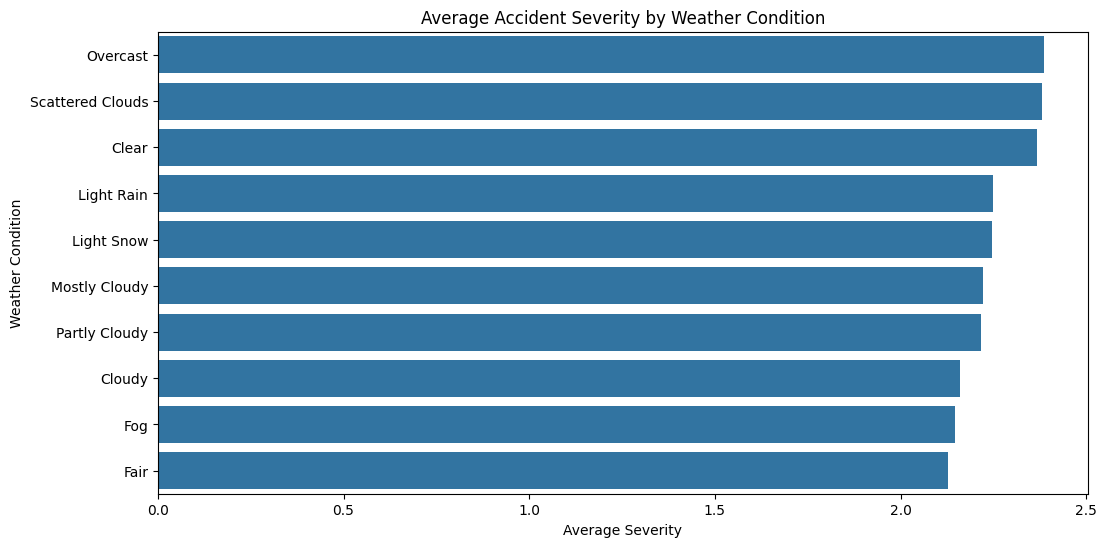

In [29]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=weather_severity.values,
    y=weather_severity.index
)

plt.title('Average Accident Severity by Weather Condition')
plt.xlabel('Average Severity')
plt.ylabel('Weather Condition')

plt.show()

### Temperature vs Severity

In [30]:
df['Temperature_Range'] = pd.cut(
    df['Temperature(F)'],
    bins=[-100, 0, 32, 50, 70, 90, 120, 220],
    labels=['Below 0°F', '0-32°F', '32-50°F', '50-70°F',
            '70-90°F', '90-120°F', 'Above 120°F']
)

temperature_severity = (
    df.groupby('Temperature_Range', observed=True)['Severity']
    .mean()
)

temperature_severity

Temperature_Range
Below 0°F      2.165686
0-32°F         2.243272
32-50°F        2.215875
50-70°F        2.212377
70-90°F        2.205400
90-120°F       2.182318
Above 120°F    2.245902
Name: Severity, dtype: float64

### Visualize Temperature vs Severity

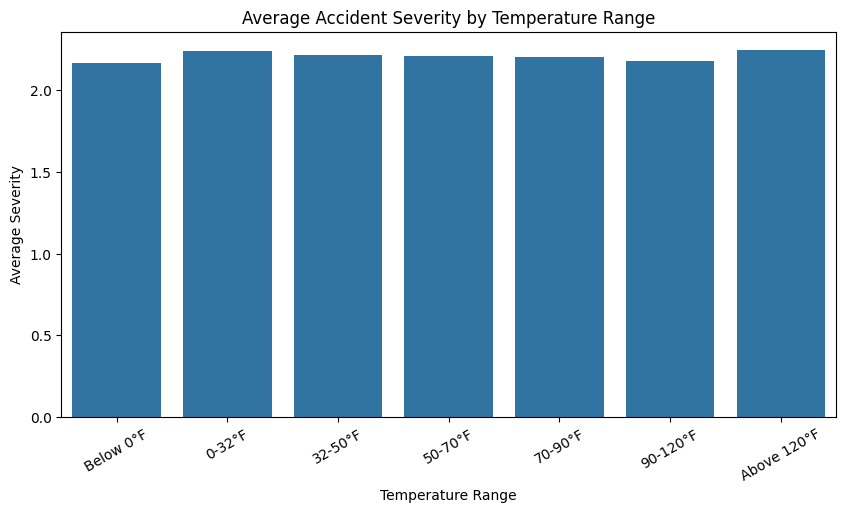

In [31]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=temperature_severity.index,
    y=temperature_severity.values
)

plt.title('Average Accident Severity by Temperature Range')
plt.xlabel('Temperature Range')
plt.ylabel('Average Severity')
plt.xticks(rotation=30)

plt.show()

### Accident Count by Temperature Range

In [32]:
temperature_counts = df['Temperature_Range'].value_counts().sort_index()
temperature_counts

Temperature_Range
Below 0°F        22253
0-32°F          593783
32-50°F        1429653
50-70°F        2728396
70-90°F        2527613
90-120°F        262782
Above 120°F         61
Name: count, dtype: int64

### Visibility vs Severity

In [33]:
df['Visibility_Range'] = pd.cut(
    df['Visibility(mi)'],
    bins=[-1, 1, 3, 5, 10, 20, 150],
    labels=['0-1 mi', '1-3 mi', '3-5 mi',
            '5-10 mi', '10-20 mi', 'Above 20 mi']
)

visibility_severity = (
    df.groupby('Visibility_Range', observed=True)['Severity']
    .mean()
)

visibility_severity

Visibility_Range
0-1 mi         2.197089
1-3 mi         2.252128
3-5 mi         2.231806
5-10 mi        2.208837
10-20 mi       2.318733
Above 20 mi    2.399323
Name: Severity, dtype: float64

### Visualize Visibility vs Severity

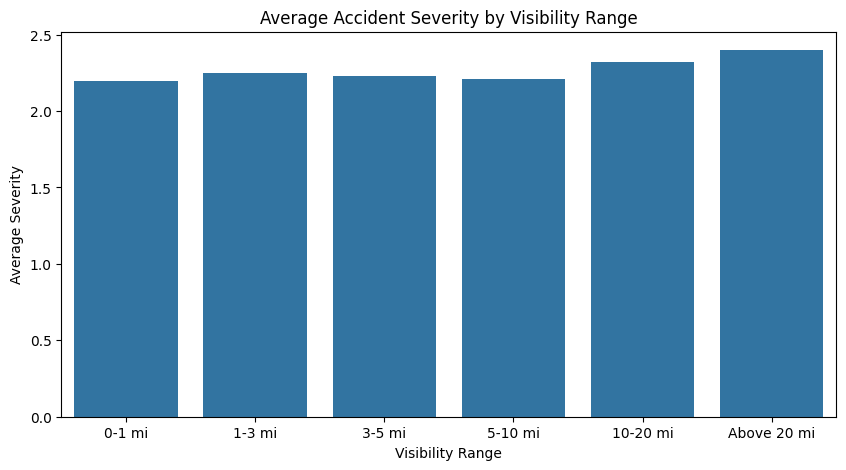

In [34]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=visibility_severity.index,
    y=visibility_severity.values
)

plt.title('Average Accident Severity by Visibility Range')
plt.xlabel('Visibility Range')
plt.ylabel('Average Severity')

plt.show()

### Accident Count by Visibility Range

In [35]:
visibility_counts = df['Visibility_Range'].value_counts().sort_index()
visibility_counts

Visibility_Range
0-1 mi          219688
1-3 mi          284423
3-5 mi          263966
5-10 mi        6752374
10-20 mi         20798
Above 20 mi      10047
Name: count, dtype: int64

### Accident Distance Analysis

In [36]:
df['Distance(mi)'].describe()

count    7.728394e+06
mean     5.618423e-01
std      1.776811e+00
min      0.000000e+00
25%      0.000000e+00
50%      3.000000e-02
75%      4.640000e-01
max      4.417500e+02
Name: Distance(mi), dtype: float64

### Detect Distance Outliers (IQR)

In [37]:
Q1 = df['Distance(mi)'].quantile(0.25)
Q3 = df['Distance(mi)'].quantile(0.75)

IQR = Q3 - Q1

upper_bound = Q3 + (1.5 * IQR)

outliers_count = (df['Distance(mi)'] > upper_bound).sum()

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Upper Bound:", upper_bound)
print("Number of Upper Outliers:", outliers_count)

Q1: 0.0
Q3: 0.464
IQR: 0.464
Upper Bound: 1.1600000000000001
Number of Upper Outliers: 963606


### Distance Distribution (Histogram)

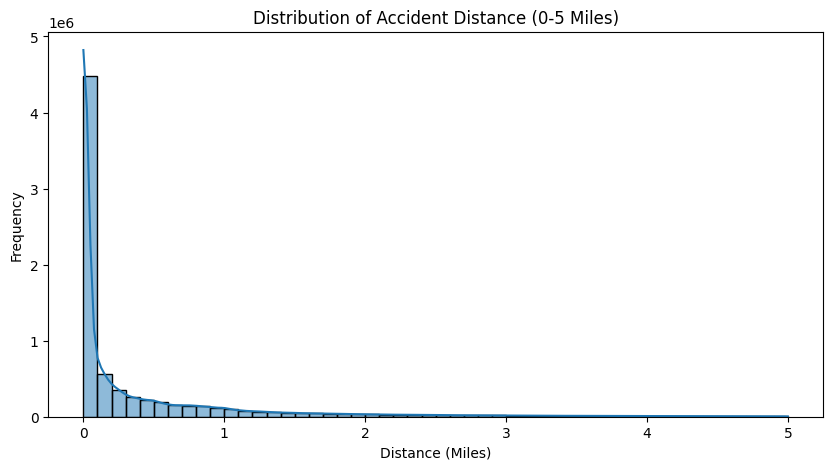

In [38]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df[df['Distance(mi)'] <= 5],
    x='Distance(mi)',
    bins=50,
    kde=True
)

plt.title('Distribution of Accident Distance (0-5 Miles)')
plt.xlabel('Distance (Miles)')
plt.ylabel('Frequency')

plt.show()

### Distance vs Severity

In [39]:
df['Distance_Category'] = pd.cut(
    df['Distance(mi)'],
    bins=[-1, 0.1, 0.5, 1.5, float('inf')],
    labels=['Very Short', 'Short', 'Medium', 'Long']
)

distance_analysis = df.groupby(
    'Distance_Category',
    observed=True
).agg(
    Accident_Count=('Severity', 'size'),
    Average_Severity=('Severity', 'mean'),
    Average_Distance=('Distance(mi)', 'mean')
)

distance_analysis

,Accident_Count,Average_Severity,Average_Distance
Distance_Category,,,
Very Short,4487459,2.241005,0.010315
Short,1389805,2.142355,0.257618
Medium,1095554,2.167728,0.887999
Long,755576,2.235968,3.924106


### Visualize Distance vs Severity

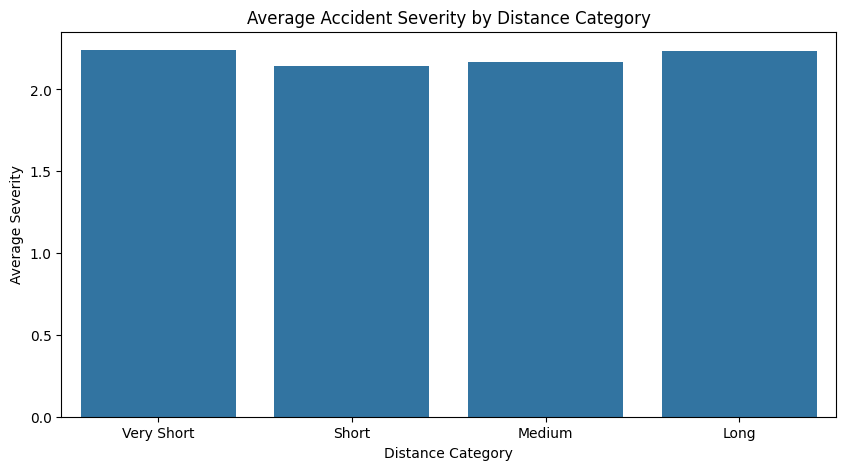

In [40]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=distance_analysis.reset_index(),
    x='Distance_Category',
    y='Average_Severity'
)

plt.title('Average Accident Severity by Distance Category')
plt.xlabel('Distance Category')
plt.ylabel('Average Severity')

plt.show()

### Pivot Table: State vs Severity

In [41]:
state_severity_pivot = pd.pivot_table(
    df,
    values='ID',
    index='State',
    columns='Severity',
    aggfunc='count',
    fill_value=0
)

state_severity_pivot

Severity,1,2,3,4
State,,,,
AL,681,76993,21542,1828
AR,37,19239,677,2827
AZ,7389,140553,17551,5116
CA,10284,1445833,271814,13502
CO,970,56105,26306,7504
CT,72,50392,16369,4172
DC,143,16489,1177,821
DE,234,11596,715,1552
FL,7083,755895,104065,13149


### Severity Distribution by State

In [42]:
state_severity_percentage = (
    state_severity_pivot
    .div(state_severity_pivot.sum(axis=1), axis=0)
    * 100
)

state_severity_percentage.round(2)

Severity,1,2,3,4
State,,,,
AL,0.67,76.20,21.32,1.81
AR,0.16,84.46,2.97,12.41
AZ,4.33,82.38,10.29,3.00
CA,0.59,83.03,15.61,0.78
CO,1.07,61.73,28.94,8.26
CT,0.10,70.97,23.05,5.88
DC,0.77,88.51,6.32,4.41
DE,1.66,82.26,5.07,11.01
FL,0.80,85.88,11.82,1.49


### Heatmap: Severity Distribution by State

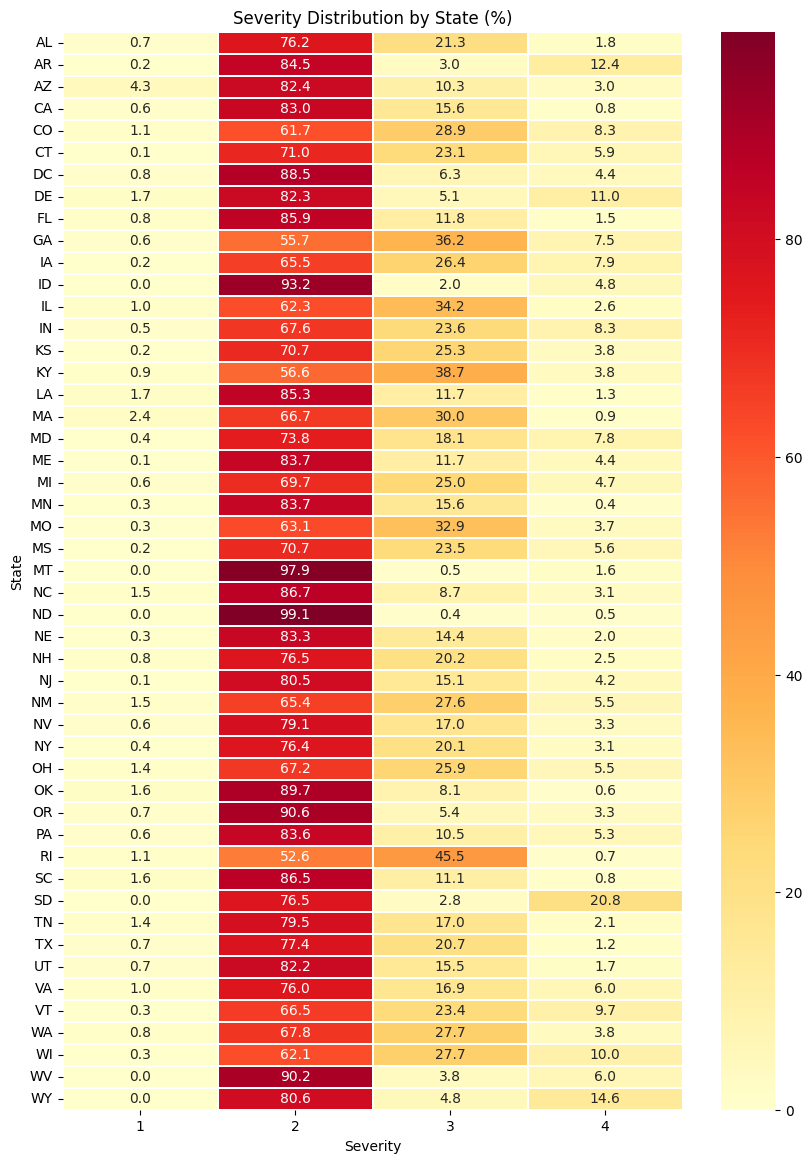

In [43]:
plt.figure(figsize=(10, 14))

sns.heatmap(
    state_severity_percentage,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    linewidths=0.3
)

plt.title('Severity Distribution by State (%)')
plt.xlabel('Severity')
plt.ylabel('State')

plt.show()

### Pivot Table: Year vs Month

In [44]:
year_month_pivot = pd.pivot_table(
    df,
    values='ID',
    index='Year',
    columns='Month',
    aggfunc='count',
    fill_value=0
)

year_month_pivot

Month,1,2,3,4,5,6,7,8,9,10,11,12
Year,,,,,,,,,,,,
2016,7,985,6330,18088,17610,30538,45780,56457,54698,55669,65040,59619
2017,55713,51679,57315,48115,41136,46272,43262,80955,76902,74975,70127,71642
2018,75093,71535,74484,72657,76529,67831,65802,76436,73354,87270,82156,70279
2019,79368,74631,69437,73020,73898,65525,68257,75269,87699,106915,81920,98364
2020,92037,85848,86054,87845,87705,100471,35229,37320,84838,130879,172234,178453
2021,152914,154935,90643,90888,101732,131472,113333,120868,134874,134287,157729,180078
2022,135900,163839,140145,196687,159566,129264,140672,152361,139016,85135,130959,188908
2023,160914,55532,30187,0,0,0,0,0,0,0,0,0


### Heatmap: Accidents by Year and Month

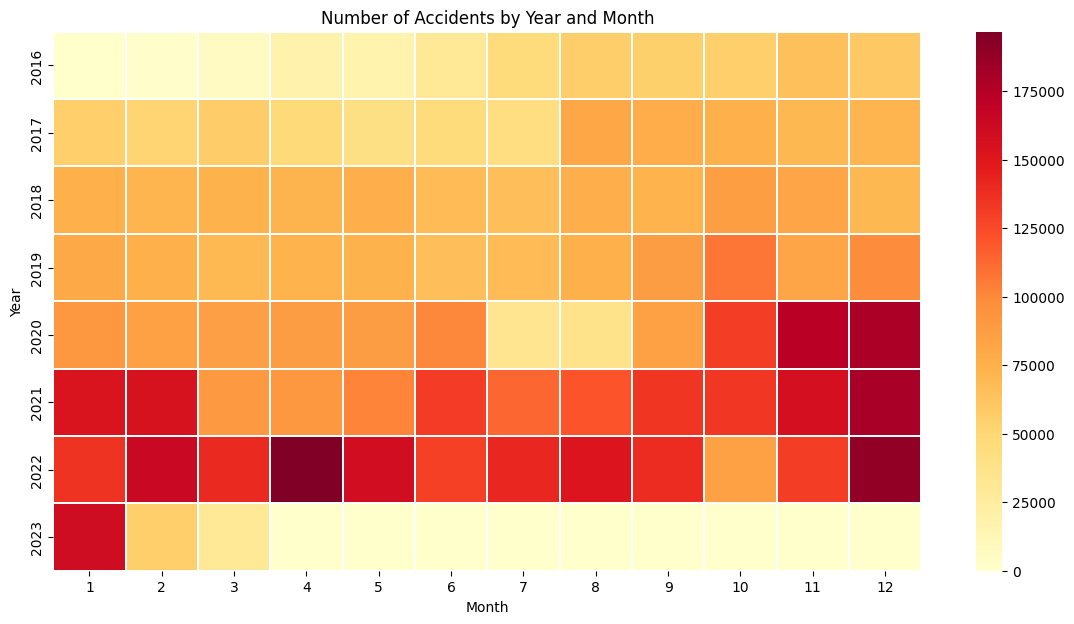

In [45]:
plt.figure(figsize=(14, 7))

sns.heatmap(
    year_month_pivot,
    cmap='YlOrRd',
    linewidths=0.3,
    fmt='.0f'
)

plt.title('Number of Accidents by Year and Month')
plt.xlabel('Month')
plt.ylabel('Year')

plt.show()

### Checking Invalid Numeric Values

In [47]:
checks = {
    'Humidity(%) outside 0-100': (
        (df['Humidity(%)'] < 0) | (df['Humidity(%)'] > 100)
    ).sum(),

    'Negative Visibility': (
        df['Visibility(mi)'] < 0
    ).sum(),

    'Negative Wind Speed': (
        df['Wind_Speed(mph)'] < 0
    ).sum(),

    'Negative Precipitation': (
        df['Precipitation(in)'] < 0
    ).sum(),

    'Negative Distance': (
        df['Distance(mi)'] < 0
    ).sum(),

    'Temperature outside -100 to 150°F': (
        (df['Temperature(F)'] < -100) |
        (df['Temperature(F)'] > 150)
    ).sum(),

    'Non-positive Pressure': (
        df['Pressure(in)'] <= 0
    ).sum()
}

pd.Series(checks, name='Invalid Values Count')

Humidity(%) outside 0-100             0
Negative Visibility                   0
Negative Wind Speed                   0
Negative Precipitation                0
Negative Distance                     0
Temperature outside -100 to 150°F    21
Non-positive Pressure                 3
Name: Invalid Values Count, dtype: int64

### Inspect Suspicious Temperature Values

In [48]:
df.loc[
    (df['Temperature(F)'] < -100) |
    (df['Temperature(F)'] > 150),
    ['Temperature(F)', 'State', 'City', 'Weather_Condition']
]

,Temperature(F),State,City,Weather_Condition
292016,161.6,TX,Pflugerville,Mostly Cloudy
504587,167.0,CT,Waterbury,Scattered Clouds
928934,196.0,AL,Tuscaloosa,Fair
929003,196.0,AL,Tuscaloosa,Fair
1278506,189.0,OH,Cleveland,T-Storm
1380133,174.0,FL,Hudson,Fair
1380135,174.0,FL,Hudson,Fair
1380565,203.0,TX,Arlington,Fair
3294817,158.0,FL,Brooksville,Clear
4205310,162.0,VA,Salem,Fair


### Inspect Invalid Pressure Values

In [49]:
df.loc[
    df['Pressure(in)'] <= 0,
    ['Pressure(in)', 'State', 'City', 'Weather_Condition']
]

,Pressure(in),State,City,Weather_Condition
2191657,0.0,SC,Rembert,Overcast
4679217,0.0,FL,Elkton,Mostly Cloudy
7384808,0.0,NC,Lumberton,NaN


### Cleaning Invalid Values

In [50]:
df.loc[df['Temperature(F)'] > 150, 'Temperature(F)'] = np.nan
df.loc[df['Pressure(in)'] <= 0, 'Pressure(in)'] = np.nan

### Verify Cleaning

In [51]:
print("Invalid Temperature Values:",
      (df['Temperature(F)'] > 150).sum())

print("Invalid Pressure Values:",
      (df['Pressure(in)'] <= 0).sum())

print("\nMissing Values After Cleaning:")

print(df[['Temperature(F)', 'Pressure(in)']].isnull().sum())

Invalid Temperature Values: 0
Invalid Pressure Values: 0

Missing Values After Cleaning:
Temperature(F)    163874
Pressure(in)      140682
dtype: int64


### Missing Values Analysis

In [52]:
missing_analysis = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().mean() * 100).round(2)
})

missing_analysis = missing_analysis[
    missing_analysis['Missing_Count'] > 0
].sort_values('Missing_Percentage', ascending=False)

missing_analysis

,Missing_Count,Missing_Percentage
End_Lat,3402762,44.03
End_Lng,3402762,44.03
Precipitation(in),2203586,28.51
Wind_Chill(F),1999019,25.87
Wind_Speed(mph),571233,7.39
Visibility(mi),177098,2.29
Visibility_Range,177098,2.29
Wind_Direction,175206,2.27
Humidity(%),174144,2.25
Weather_Condition,173459,2.24


### Missing Values by Source

In [53]:
missing_by_source = (
    df.groupby('Source')[
        ['End_Lat', 'End_Lng',
         'Precipitation(in)', 'Wind_Chill(F)',
         'Wind_Speed(mph)']
    ]
    .apply(lambda group: group.isnull().mean() * 100)
)

missing_by_source.round(2)

,End_Lat,End_Lng,Precipitation(in),Wind_Chill(F),Wind_Speed(mph)
Source,,,,,
Source1,0.0,0.0,14.45,12.43,4.80
Source2,100.0,100.0,46.98,43.57,10.81
Source3,100.0,100.0,26.23,22.01,6.41


### Missing Values by Source (Counts)

In [54]:
source_counts = df['Source'].value_counts()

source_missing_summary = (
    df.groupby('Source')[
        ['End_Lat', 'End_Lng',
         'Precipitation(in)', 'Wind_Chill(F)',
         'Wind_Speed(mph)']
    ]
    .agg(lambda column: column.isnull().sum())
)

source_missing_summary.insert(
    0, 'Total_Accidents', source_counts
)

source_missing_summary

,Total_Accidents,End_Lat,End_Lng,Precipitation(in),Wind_Chill(F),Wind_Speed(mph)
Source,,,,,,
Source1,4325632,0,0,625079,537575,207813
Source2,3305373,3305373,3305373,1552962,1440007,357176
Source3,97389,97389,97389,25545,21437,6244


### Categorical Missing Values by Source

In [55]:
categorical_missing = (
    df.groupby('Source')[
        ['Weather_Condition', 'Wind_Direction',
         'Sunrise_Sunset', 'Civil_Twilight']
    ]
    .apply(lambda group: group.isnull().mean() * 100)
)

categorical_missing.round(2)

,Weather_Condition,Wind_Direction,Sunrise_Sunset,Civil_Twilight
Source,,,,
Source1,2.51,2.79,0.50,0.50
Source2,1.91,1.59,0.05,0.05
Source3,1.98,2.21,0.14,0.14


### Missing Values by State

In [56]:
missing_by_state = (
    df.groupby('State')[
        ['Temperature(F)', 'Humidity(%)',
         'Pressure(in)', 'Visibility(mi)',
         'Wind_Speed(mph)', 'Precipitation(in)']
    ]
    .apply(lambda group: group.isnull().mean() * 100)
)

missing_by_state.round(2)

,Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in)
State,,,,,,
AL,1.33,1.63,1.14,1.24,5.69,18.79
AR,2.01,2.32,1.86,2.11,3.45,7.31
AZ,2.94,3.03,2.70,2.70,8.28,32.23
CA,2.64,2.78,2.13,2.30,9.35,32.51
CO,1.41,1.50,1.19,1.79,6.83,30.87
CT,0.42,0.53,0.20,0.27,4.13,22.43
DC,4.97,4.97,4.65,4.87,6.05,12.89
DE,0.57,0.59,0.27,0.94,2.62,19.66
FL,1.57,1.76,0.86,1.30,3.81,19.05


### Average Weather Values by State

In [57]:
weather_by_state = df.groupby('State')[
    ['Temperature(F)', 'Humidity(%)',
     'Pressure(in)', 'Visibility(mi)',
     'Wind_Speed(mph)', 'Precipitation(in)']
].mean()

weather_by_state.round(2)

,Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in)
State,,,,,,
AL,66.48,68.99,29.71,9.09,6.39,0.01
AR,59.85,71.03,29.62,8.83,7.07,0.01
AZ,72.65,32.29,28.42,10.21,7.12,0.00
CA,63.90,58.71,29.63,9.09,6.55,0.00
CO,47.54,52.38,25.79,11.28,8.51,0.00
CT,54.62,66.33,29.88,8.93,7.88,0.01
DC,59.38,62.84,29.98,9.47,8.15,0.00
DE,58.94,67.16,29.98,9.16,8.92,0.01
FL,75.37,71.36,30.02,9.51,8.48,0.01


### Fill Missing Weather Values by State

In [58]:
columns_to_fill = [
    'Temperature(F)',
    'Humidity(%)',
    'Pressure(in)',
    'Visibility(mi)',
    'Wind_Speed(mph)'
]

for col in columns_to_fill:
    df[col] = df[col].fillna(
        df.groupby('State')[col].transform('mean')
    )

### Verify Missing Values After Imputation

In [59]:
df[columns_to_fill].isnull().sum()

Temperature(F)     0
Humidity(%)        0
Pressure(in)       0
Visibility(mi)     0
Wind_Speed(mph)    0
dtype: int64

### Final Missing Values Overview

In [60]:
remaining_missing = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (
        df.isnull().mean() * 100
    ).round(2)
})

remaining_missing = remaining_missing[
    remaining_missing['Missing_Count'] > 0
].sort_values('Missing_Percentage', ascending=False)

remaining_missing

,Missing_Count,Missing_Percentage
End_Lat,3402762,44.03
End_Lng,3402762,44.03
Precipitation(in),2203586,28.51
Wind_Chill(F),1999019,25.87
Visibility_Range,177098,2.29
Wind_Direction,175206,2.27
Weather_Condition,173459,2.24
Temperature_Range,163853,2.12
Weather_Timestamp,120228,1.56
Astronomical_Twilight,23246,0.30


### Recreate Derived Features

In [61]:
df['Temperature_Range'] = pd.cut(
    df['Temperature(F)'],
    bins=[-100, 0, 32, 50, 70, 90, 120, 220],
    labels=[
        'Below 0°F', '0-32°F', '32-50°F',
        '50-70°F', '70-90°F', '90-120°F',
        'Above 120°F'
    ]
)

df['Visibility_Range'] = pd.cut(
    df['Visibility(mi)'],
    bins=[-1, 1, 3, 5, 10, 20, 150],
    labels=[
        '0-1 mi', '1-3 mi', '3-5 mi',
        '5-10 mi', '10-20 mi', 'Above 20 mi'
    ]
)

### Validate Derived Features

In [62]:
print("Temperature Range:")
print(df['Temperature_Range'].value_counts().sort_index())

print("\nVisibility Range:")
print(df['Visibility_Range'].value_counts().sort_index())

print("\nMissing Values:")
print(df[['Temperature_Range', 'Visibility_Range']].isnull().sum())

Temperature Range:
Temperature_Range
Below 0°F        22253
0-32°F          594414
32-50°F        1435817
50-70°F        2865390
70-90°F        2547698
90-120°F        262782
Above 120°F         40
Name: count, dtype: int64

Visibility Range:
Visibility_Range
0-1 mi          219688
1-3 mi          284423
3-5 mi          263966
5-10 mi        6923230
10-20 mi         27040
Above 20 mi      10047
Name: count, dtype: int64

Missing Values:
Temperature_Range    0
Visibility_Range     0
dtype: int64


### Correlation Analysis

In [63]:
correlation_columns = [
    'Severity',
    'Temperature(F)',
    'Humidity(%)',
    'Pressure(in)',
    'Visibility(mi)',
    'Wind_Speed(mph)',
    'Distance(mi)',
    'Hour',
    'Month'
]

correlation_matrix = df[correlation_columns].corr()

correlation_matrix.round(2)

,Severity,Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Distance(mi),Hour,Month
Severity,1.00,-0.02,0.02,0.04,-0.00,0.04,0.03,0.01,-0.01
Temperature(F),-0.02,1.00,-0.33,0.11,0.22,0.03,-0.05,0.18,0.13
Humidity(%),0.02,-0.33,1.00,0.12,-0.38,-0.17,0.01,-0.27,0.04
Pressure(in),0.04,0.11,0.12,1.00,0.04,-0.03,-0.09,-0.01,-0.00
Visibility(mi),-0.00,0.22,-0.38,0.04,1.00,0.01,-0.04,0.09,0.02
Wind_Speed(mph),0.04,0.03,-0.17,-0.03,0.01,1.00,0.01,0.13,-0.08
Distance(mi),0.03,-0.05,0.01,-0.09,-0.04,0.01,1.00,-0.00,0.00
Hour,0.01,0.18,-0.27,-0.01,0.09,0.13,-0.00,1.00,0.02
Month,-0.01,0.13,0.04,-0.00,0.02,-0.08,0.00,0.02,1.00


### Correlation Heatmap

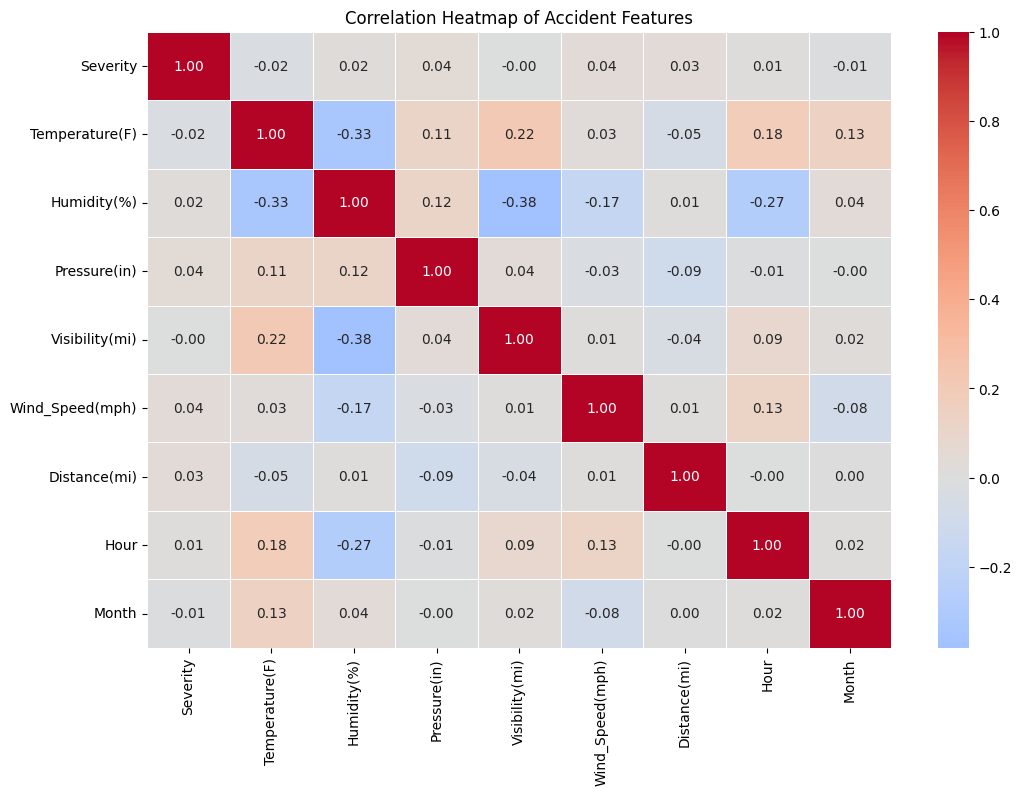

In [64]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5
)

plt.title('Correlation Heatmap of Accident Features')
plt.show()

### Final Data Quality Check

In [65]:
final_checks = {
    'Duplicate Rows': df.duplicated().sum(),
    'Duplicate IDs': df['ID'].duplicated().sum(),
    'Invalid Humidity': (
        (df['Humidity(%)'] < 0) | (df['Humidity(%)'] > 100)
    ).sum(),
    'Invalid Temperature': (
        (df['Temperature(F)'] < -100) |
        (df['Temperature(F)'] > 150)
    ).sum(),
    'Invalid Pressure': (
        (df['Pressure(in)'] <= 0)
    ).sum(),
    'Negative Visibility': (
        df['Visibility(mi)'] < 0
    ).sum(),
    'Negative Wind Speed': (
        df['Wind_Speed(mph)'] < 0
    ).sum(),
    'Negative Distance': (
        df['Distance(mi)'] < 0
    ).sum()
}

pd.Series(final_checks, name='Count')

Duplicate Rows         0
Duplicate IDs          0
Invalid Humidity       0
Invalid Temperature    0
Invalid Pressure       0
Negative Visibility    0
Negative Wind Speed    0
Negative Distance      0
Name: Count, dtype: int64

### Final Missing Values Report

In [66]:
final_missing = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (df.isnull().mean() * 100).round(2)
})

final_missing = final_missing[
    final_missing['Missing Count'] > 0
].sort_values('Missing Percentage', ascending=False)

final_missing

,Missing Count,Missing Percentage
End_Lat,3402762,44.03
End_Lng,3402762,44.03
Precipitation(in),2203586,28.51
Wind_Chill(F),1999019,25.87
Wind_Direction,175206,2.27
Weather_Condition,173459,2.24
Weather_Timestamp,120228,1.56
Civil_Twilight,23246,0.30
Sunrise_Sunset,23246,0.30
Nautical_Twilight,23246,0.30


### Final Dataset Overview

In [67]:
print("Final Dataset Shape:", df.shape)

print("\nTotal Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

print("\nMemory Usage:")
print(round(df.memory_usage(deep=True).sum() / (1024 ** 3), 2), "GB")

Final Dataset Shape: (7728394, 52)

Total Rows: 7728394
Total Columns: 52

Memory Usage:
9.14 GB


### Key Findings Summary

In [68]:
print("US ACCIDENTS — KEY FINDINGS")
print("-" * 40)

print("Total Accidents:", len(df))

print("\nSeverity Distribution (%):")
print((df['Severity'].value_counts(normalize=True) * 100).round(2))

print("\nTop 5 States:")
print(df['State'].value_counts().head(5))

print("\nTop 5 Accident Hours:")
print(df['Hour'].value_counts().head(5))

print("\nTop 5 Accident Months:")
print(df['Month'].value_counts().head(5))

print("\nAverage Accident Severity:", round(df['Severity'].mean(), 2))

US ACCIDENTS — KEY FINDINGS
----------------------------------------
Total Accidents: 7728394

Severity Distribution (%):
Severity
2    79.67
3    16.81
4     2.65
1     0.87
Name: proportion, dtype: float64

Top 5 States:
State
CA    1741433
FL     880192
TX     582837
SC     382557
NY     347960
Name: count, dtype: int64

Top 5 Accident Hours:
Hour
7     587472
16    581969
8     577576
17    576015
15    525855
Name: count, dtype: int64

Top 5 Accident Months:
Month
12    847343
11    760165
1     751946
10    675130
2     658984
Name: count, dtype: int64

Average Accident Severity: 2.21


### Final Conclusion Data

In [69]:
monthly_counts = df['Month'].value_counts()
hourly_counts = df['Hour'].value_counts()

print("Monthly Analysis")
print("Highest Month:", monthly_counts.idxmax(),
      "-", monthly_counts.max())
print("Lowest Month:", monthly_counts.idxmin(),
      "-", monthly_counts.min())

print("\nHourly Analysis")
print("Highest Hour:", hourly_counts.idxmax(),
      "-", hourly_counts.max())
print("Lowest Hour:", hourly_counts.idxmin(),
      "-", hourly_counts.min())

Monthly Analysis
Highest Month: 12 - 847343
Lowest Month: 7 - 512335

Hourly Analysis
Highest Hour: 7 - 587472
Lowest Hour: 3 - 83863


### Final Conclusion

#### 1. Key Data Quality Issues

The dataset contained several data quality issues:

Missing geographical coordinates (End_Lat, End_Lng) in approximately 44% of records.

Significant missing weather information, especially Precipitation(in) (28.51%) and Wind_Chill(F) (25.87%).

Invalid values, including 21 temperature readings above 150°F and 3 non-positive pressure readings.

#### 2. Data Cleaning Decisions

Checked for duplicate records and duplicate IDs; none were found.

Replaced invalid temperature and pressure values with missing values.

Imputed missing temperature, humidity, pressure, visibility, and wind speed using state-level means.

Kept missing coordinates and other incomplete fields where reliable replacement values were unavailable.

Created additional features such as Year, Month, Hour, Temperature Range, and Visibility Range.

#### 3. Main Findings

The dataset contains 7,728,394 accident records.

Severity 2 represents approximately 79.67% of all accidents.

California recorded the highest number of accidents (1,741,433).

December had the highest monthly accident count (847,343), while July had the lowest (512,335).

7 AM was the busiest hour (587,472 accidents), while 3 AM had the fewest (83,863).

Correlation analysis showed no strong linear relationship between Severity and the selected numerical features.

#### 4. Business Recommendations

Traffic Management: Consider additional traffic monitoring and congestion management around morning and afternoon peak hours.

Seasonal Planning: Review traffic safety measures during high-count months, particularly December.

Data Quality Improvement: Improve weather and geographical data collection to support more reliable future analysis.

#### 5. Final Note

This analysis identifies patterns and associations in recorded accident data. Accident counts do not represent population-adjusted or traffic-exposure-adjusted risk, and correlation does not establish causation. The 2023 records are also incomplete and should be interpreted cautiously.